## 1. Assignment -4-
**Clustering Assignment: Reproducible Segmentation and Diagnostics (Wine Dataset)**


## 2. Context & Scenario
You are working on an ML Systems team supporting a product analytics group that needs stable, interpretable clusters for downstream reporting and decision support. The organization plans to operationalize clustering outputs in a recurring pipeline, so reproducibility, guardrails, and monitoring are mandatory. Your task is to implement clustering workflows, justify model choices using diagnostics, and assess stability risks under re-runs and potential data drift. You must communicate cluster meaning responsibly and propose production monitoring signals that would detect degradation.


## 3. Dataset
- **Dataset name:** UCI Wine (via scikit-learn)
- **Access links:**
  - Load via scikit-learn: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html
  - Dataset page (UCI): https://archive.ics.uci.edu/ml/datasets/wine
- **What it contains:**
    - Each row represents a wine sample; features are 13 numeric chemical measurements (e.g., alcohol, flavanoids).
    - The dataset contains ~178 samples. It includes a cultivar label (3 classes) that you must treat as **metadata only** for sanity checking, not as a supervised target.


## 4. Machine Learning Tasks
- **Data loading:** Load the dataset into a Pandas DataFrame; separate features from metadata label (do not train supervised models).
- **Validation/guardrails:** Implement minimum schema checks (missingness, duplicates, non-finite values) and fail fast; document your schema contract.
- **EDA:** Summarize distributions and potential skew/outliers; identify features likely to dominate distance computations.
- **Preprocessing:** Apply `StandardScaler` and justify scaling; optionally apply a monotone transform (e.g., `log1p`) and justify when/why.
- **K-Means:** Train a reproducible baseline `KMeans` (fixed `random_state`, justified `n_init`); visualize clusters in 2D via PCA.
- **Model selection:** Choose *k* using **Elbow + Silhouette + one additional diagnostic** (e.g., stability across seeds using ARI, centroid-distance distribution, or cluster proportion sensitivity).
- **Second method:** Implement **Hierarchical** (linkage + dendrogram + cut) *or* **DBSCAN** (parameter sweep); compare behavior to K-means.
- **Cluster profiling + interpretation:** Provide per-cluster summaries and concise segment narratives; include a cautious sanity check against metadata labels (e.g., ARI or contingency table).
- **Systems considerations (monitoring/drift):** Propose what to log, what to monitor (drift + stability + quality proxies), and retraining/rollback triggers; discuss compute and operational costs.


## 5. Deliverables
- Executed Jupyter notebook with code, plots, and brief Markdown interpretations.
- A short “production readiness” section: guardrails, reproducibility record, monitoring plan, and retraining/rollback criteria.
- Optional appendix cell: experiment log table (parameters, seeds, metrics, timestamps).


## 6. Grading Rubric (100 points)
- **Code correctness & notebook hygiene — 25 pts** (runs end-to-end; clear structure; appropriate use of numpy/pandas/sklearn/matplotlib).
- **Data quality & validation — 15 pts** (schema guardrails implemented; failure modes identified; validation rationale).
- **EDA quality — 10 pts** (relevant summaries; identifies scaling/transform needs; concise insights).
- **Modeling & evaluation/diagnostics — 25 pts** (K-means baseline; k-selection via elbow + silhouette + additional diagnostic; second clustering method with comparison).
- **Interpretation & cluster profiling — 15 pts** (meaningful profiles; cautious narratives; correct use of metadata as sanity check only).
- **ML-systems thinking — 10 pts** (reproducibility artifacts, monitoring/drift signals, cost/latency considerations, rollback/retraining triggers).


_____________________________________________________________________________________________________________________________________________________________________________________

## Schema Contract

The dataset should have 178 observations and 13 numeric chemical features. The given cultivar label is metadata only. It is critical to check for missing values, duplicates, data types of numeric columns, and whether the numeric columns have finite values before clustering analysis. The data must be standardized since the chemical features are in different units and have a different scale, and using Euclidean distance without standardization will produce incorrect results because of the different variances.

## Setup & Reproducibility

The seed and K-Means initialization count are fixed near the top of the notebook. A production experiment log should also record the dataset version/hash, feature schema, preprocessing parameters, clustering parameters, selected `k`, metrics, software versions, and timestamp.

In [23]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
KMEANS_N_INIT = 20
K_RANGE = range(2, 9)

np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Random state:", RANDOM_STATE)
print("K-Means n_init:", KMEANS_N_INIT)

Python: 3.13.9
pandas: 2.3.3
NumPy: 2.3.5
Random state: 42
K-Means n_init: 20


## Load the Wine Dataset

In [24]:
wine_data = load_wine()

X_raw = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
metadata = pd.Series(wine_data.target, name="cultivar")

print("Feature shape:", X_raw.shape)
print("Metadata shape:", metadata.shape)
display(X_raw.head())
display(metadata.value_counts().sort_index().rename("count").to_frame())

Feature shape: (178, 13)
Metadata shape: (178,)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.230,1.710,2.430,15.600,127.000,2.800,3.060,0.280,2.290,5.640,1.040,3.920,"1,065.000"
1,13.200,1.780,2.140,11.200,100.000,2.650,2.760,0.260,1.280,4.380,1.050,3.400,"1,050.000"
2,13.160,2.360,2.670,18.600,101.000,2.800,3.240,0.300,2.810,5.680,1.030,3.170,"1,185.000"
3,14.370,1.950,2.500,16.800,113.000,3.850,3.490,0.240,2.180,7.800,0.860,3.450,"1,480.000"
4,13.240,2.590,2.870,21.000,118.000,2.800,2.690,0.390,1.820,4.320,1.040,2.930,735.000


,count
cultivar,
0,59
1,71
2,48


## Data Validation & Guardrails

Duplicate rows are reported before modeling. They are not deleted automatically, since an exact duplicate could represent a repeated legitimate observation, and the correct course of action depends on how the data were collected. The cultivar label is kept separate from the feature matrix. Using it for clustering would leak the metadata into an unsupervised model.

In [25]:
assert X_raw.shape == (178, 13), "Unexpected dataset shape."
assert X_raw.isna().sum().sum() == 0, "Missing values detected."
assert np.isfinite(X_raw.to_numpy()).all(), "Non-finite values detected."
assert all(np.issubdtype(dtype, np.number) for dtype in X_raw.dtypes), "Non-numeric feature detected."

duplicate_count = int(X_raw.duplicated().sum())

print("Missing values:", int(X_raw.isna().sum().sum()))
print("Non-finite values:", int((~np.isfinite(X_raw.to_numpy())).sum()))
print("Exact duplicate feature rows:", duplicate_count)
print("Validation passed.")

Missing values: 0
Non-finite values: 0
Exact duplicate feature rows: 0
Validation passed.


## EDA: Distributions, Skewness, & Distance Dominance

The range of raw feature values varies significantly, which affects the clustering ability of the K-Means algorithm since it uses the Euclidean distance. For this reason, the StandardScaler is applied to center the data and reduce the difference in scales between the features. The transformation of the data using a monotonic function like `log1p` may resolve some issues with heavily right-skewed positive features, but it is not always required. The main preprocessing step for this assignment is data standardization.

In [26]:
eda_summary = X_raw.describe().T
eda_summary["skewness"] = X_raw.skew()
eda_summary["kurtosis"] = X_raw.kurt()
eda_summary["range"] = eda_summary["max"] - eda_summary["min"]

display(eda_summary.sort_values("range", ascending=False))

print("Features with the largest raw ranges:")
display(eda_summary[["min", "max", "range", "skewness", "kurtosis"]]
        .sort_values("range", ascending=False)
        .head(8))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,range
proline,178.000,746.893,314.907,278.000,500.500,673.500,985.000,"1,680.000",0.768,-0.248,"1,402.000"
magnesium,178.000,99.742,14.282,70.000,88.000,98.000,107.000,162.000,1.098,2.105,92.000
alcalinity_of_ash,178.000,19.495,3.340,10.600,17.200,19.500,21.500,30.000,0.213,0.488,19.400
color_intensity,178.000,5.058,2.318,1.280,3.220,4.690,6.200,13.000,0.869,0.382,11.720
malic_acid,178.000,2.336,1.117,0.740,1.603,1.865,3.083,5.800,1.040,0.299,5.060
flavanoids,178.000,2.029,0.999,0.340,1.205,2.135,2.875,5.080,0.025,-0.880,4.740
alcohol,178.000,13.001,0.812,11.030,12.362,13.050,13.678,14.830,-0.051,-0.852,3.800
proanthocyanins,178.000,1.591,0.572,0.410,1.250,1.555,1.950,3.580,0.517,0.555,3.170
total_phenols,178.000,2.295,0.626,0.980,1.742,2.355,2.800,3.880,0.087,-0.836,2.900
od280/od315_of_diluted_wines,178.000,2.612,0.710,1.270,1.938,2.780,3.170,4.000,-0.307,-1.086,2.730


Features with the largest raw ranges:


,min,max,range,skewness,kurtosis
proline,278.000,"1,680.000","1,402.000",0.768,-0.248
magnesium,70.000,162.000,92.000,1.098,2.105
alcalinity_of_ash,10.600,30.000,19.400,0.213,0.488
color_intensity,1.280,13.000,11.720,0.869,0.382
malic_acid,0.740,5.800,5.060,1.040,0.299
flavanoids,0.340,5.080,4.740,0.025,-0.880
alcohol,11.030,14.830,3.800,-0.051,-0.852
proanthocyanins,0.410,3.580,3.170,0.517,0.555


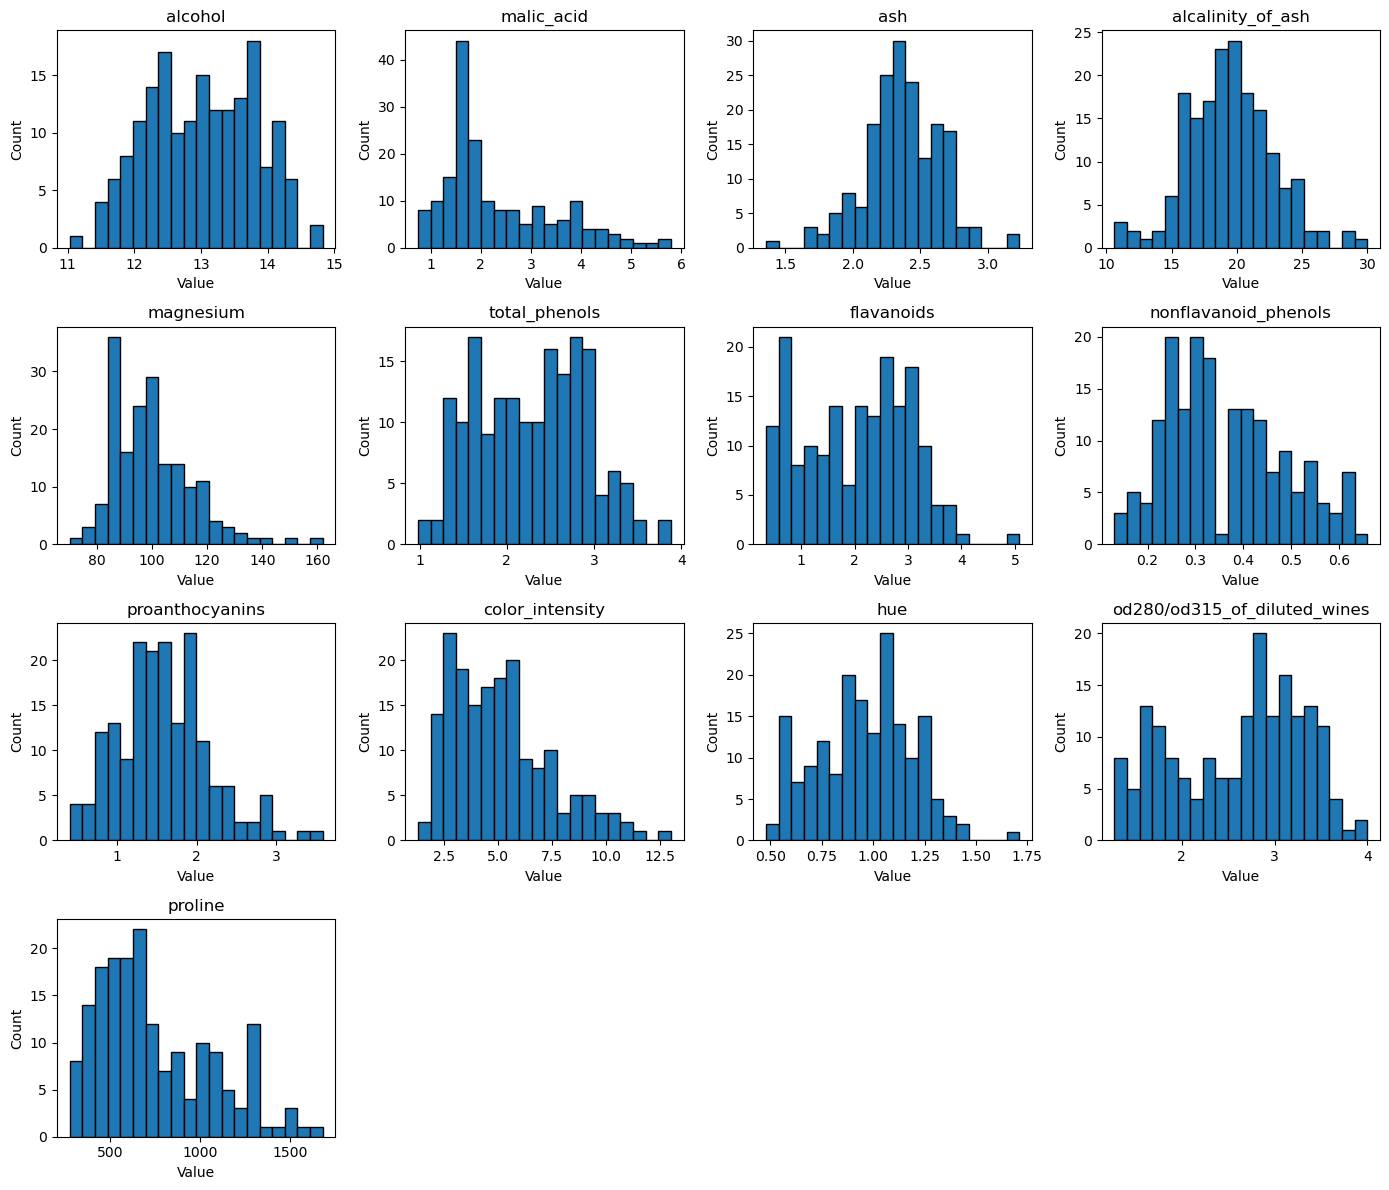

In [27]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
axes = axes.ravel()

for i, column in enumerate(X_raw.columns):
    axes[i].hist(X_raw[column], bins=20, edgecolor="black")
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Count")

for i in range(len(X_raw.columns), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Standardize Features

In [28]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

X_scaled_df = pd.DataFrame(X_scaled, columns=X_raw.columns)

display(X_scaled_df.mean().round(3).rename("mean").to_frame())
display(X_scaled_df.std(ddof=0).round(3).rename("std").to_frame())

,mean
alcohol,0.000
malic_acid,0.000
ash,-0.000
alcalinity_of_ash,-0.000
magnesium,-0.000
total_phenols,-0.000
flavanoids,0.000
nonflavanoid_phenols,-0.000
proanthocyanins,-0.000
color_intensity,-0.000


,std
alcohol,1.000
malic_acid,1.000
ash,1.000
alcalinity_of_ash,1.000
magnesium,1.000
total_phenols,1.000
flavanoids,1.000
nonflavanoid_phenols,1.000
proanthocyanins,1.000
color_intensity,1.000


## K-Means Baseline

In [29]:
kmeans_baseline = KMeans(
    n_clusters=3,
    random_state=RANDOM_STATE,
    n_init=KMEANS_N_INIT
)

baseline_labels = kmeans_baseline.fit_predict(X_scaled)

print("k:", 3)
print("Inertia:", round(kmeans_baseline.inertia_, 3))
print("Silhouette:", round(silhouette_score(X_scaled, baseline_labels), 3))
display(pd.Series(baseline_labels).value_counts().sort_index().rename("count").to_frame())

k: 3
Inertia: 1277.928
Silhouette: 0.285


,count
0,65
1,51
2,62


## PCA Visualization

PC1 explained variance: 0.362
PC2 explained variance: 0.192
Total: 0.554


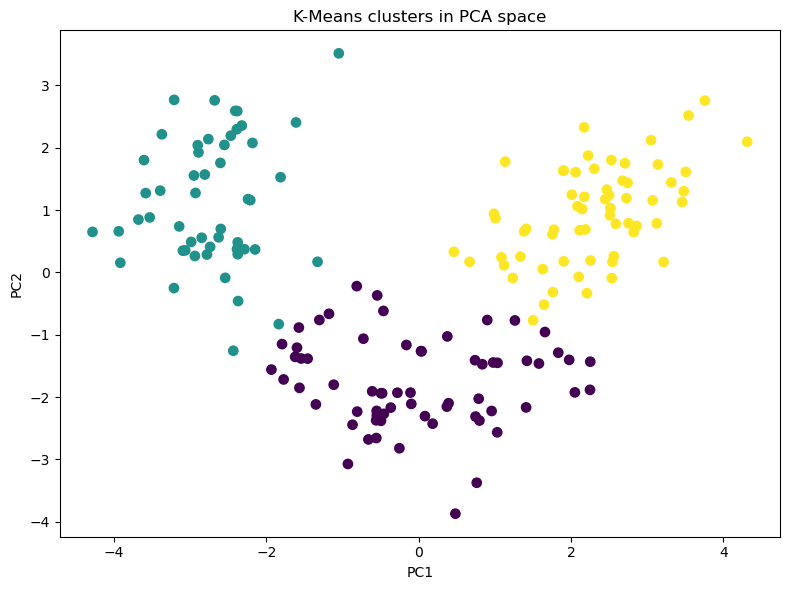

In [30]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PC1 explained variance:", round(pca.explained_variance_ratio_[0], 3))
print("PC2 explained variance:", round(pca.explained_variance_ratio_[1], 3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=baseline_labels, s=45)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means clusters in PCA space")
plt.tight_layout()
plt.show()

## Model Selection: Elbow, Silhouette, & Stability

Three diagnostics are used:

- Elbow/inertia: shows how within-cluster squared distance changes as `k` increases.
- Silhouette: measures within-cluster cohesion relative to separation from other clusters.
- Seed stability: compares cluster assignments across multiple K-Means random seeds using ARI.

Using multiple diagnostics is safer than selecting `k` from one metric alone.

In [31]:
k_results = []

for k in K_RANGE:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=KMEANS_N_INIT
    )
    labels = model.fit_predict(X_scaled)

    k_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
        "smallest_cluster": pd.Series(labels).value_counts().min(),
        "largest_cluster": pd.Series(labels).value_counts().max()
    })

k_results_df = pd.DataFrame(k_results)
display(k_results_df)

,k,inertia,silhouette,smallest_cluster,largest_cluster
0,2,"1,658.759",0.259,87,91
1,3,"1,277.928",0.285,51,65
2,4,"1,175.352",0.259,29,55
3,5,"1,107.007",0.232,23,55
4,6,"1,046.002",0.237,5,53
5,7,981.595,0.204,3,54
6,8,935.201,0.157,3,39


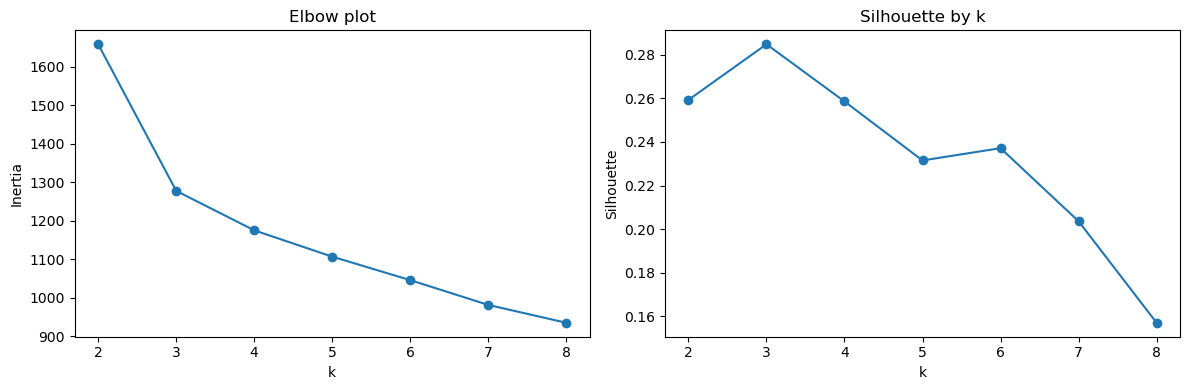

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_results_df["k"], k_results_df["inertia"], marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow plot")

axes[1].plot(k_results_df["k"], k_results_df["silhouette"], marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].set_title("Silhouette by k")

plt.tight_layout()
plt.show()

In [33]:
stability_seeds = [0, 1, 2, 3, 4, 42]
stability_rows = []

for k in K_RANGE:
    labels_by_seed = []

    for seed in stability_seeds:
        model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=KMEANS_N_INIT
        )
        labels_by_seed.append(model.fit_predict(X_scaled))

    ari_values = []
    for i in range(len(labels_by_seed)):
        for j in range(i + 1, len(labels_by_seed)):
            ari_values.append(
                adjusted_rand_score(labels_by_seed[i], labels_by_seed[j])
            )

    stability_rows.append({
        "k": k,
        "mean_pairwise_ARI": np.mean(ari_values),
        "std_pairwise_ARI": np.std(ari_values),
        "min_pairwise_ARI": np.min(ari_values)
    })

stability_df = pd.DataFrame(stability_rows)
display(stability_df)

,k,mean_pairwise_ARI,std_pairwise_ARI,min_pairwise_ARI
0,2,0.833,0.236,0.498
1,3,1.000,0.000,1.000
2,4,0.886,0.121,0.708
3,5,0.822,0.059,0.723
4,6,0.750,0.113,0.578
5,7,0.666,0.085,0.556
6,8,0.736,0.061,0.638


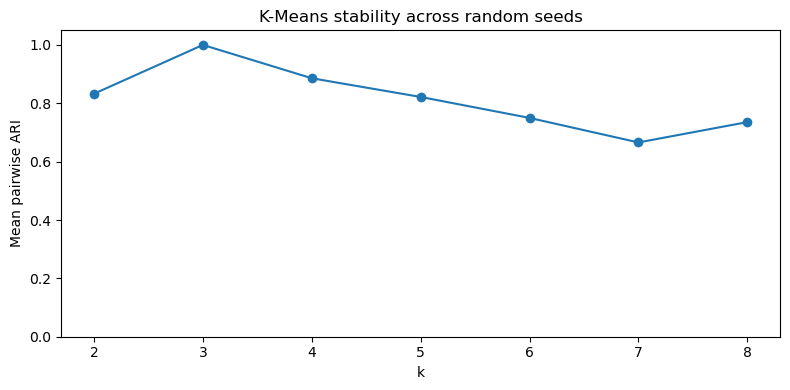

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(stability_df["k"], stability_df["mean_pairwise_ARI"], marker="o")
plt.xlabel("k")
plt.ylabel("Mean pairwise ARI")
plt.title("K-Means stability across random seeds")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Selected Operating Value

`k=3` is retained as the documented operating choice. The choice should be reported together with the elbow, silhouette, stability, and cluster-size results rather than presenting `k=3` as a universally correct number of segments.

In [35]:
SELECTED_K = 3

selected_k_row = k_results_df[k_results_df["k"] == SELECTED_K].iloc[0]
selected_stability_row = stability_df[stability_df["k"] == SELECTED_K].iloc[0]

print("Selected k:", SELECTED_K)
print("Inertia:", round(selected_k_row["inertia"], 3))
print("Silhouette:", round(selected_k_row["silhouette"], 3))
print("Mean stability ARI:", round(selected_stability_row["mean_pairwise_ARI"], 3))
print("Minimum stability ARI:", round(selected_stability_row["min_pairwise_ARI"], 3))

Selected k: 3
Inertia: 1277.928
Silhouette: 0.285
Mean stability ARI: 1.0
Minimum stability ARI: 1.0


## Final K-Means & Cluster Profiles

In [36]:
kmeans_final = KMeans(
    n_clusters=SELECTED_K,
    random_state=RANDOM_STATE,
    n_init=KMEANS_N_INIT
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()
cluster_props = (cluster_counts / len(kmeans_labels)).rename("proportion")

display(pd.concat([
    cluster_counts.rename("count"),
    cluster_props
], axis=1))

,count,proportion
0,65,0.365
1,51,0.287
2,62,0.348


In [37]:
profile_original = X_raw.copy()
profile_original["cluster"] = kmeans_labels

cluster_means = profile_original.groupby("cluster").mean()
display(cluster_means)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,12.251,1.897,2.231,20.063,92.738,2.248,2.050,0.358,1.624,2.973,1.063,2.803,510.169
1,13.134,3.307,2.418,21.241,98.667,1.684,0.819,0.452,1.146,7.235,0.692,1.697,619.059
2,13.677,1.998,2.466,17.463,107.968,2.848,3.003,0.292,1.922,5.454,1.065,3.163,"1,100.226"


In [38]:
scaled_profile = X_scaled_df.copy()
scaled_profile["cluster"] = kmeans_labels
scaled_cluster_means = scaled_profile.groupby("cluster").mean()

display(scaled_cluster_means.round(2))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,
0,-0.930,-0.390,-0.490,0.170,-0.490,-0.080,0.020,-0.030,0.060,-0.900,0.460,0.270,-0.750
1,0.160,0.870,0.190,0.520,-0.080,-0.980,-1.220,0.730,-0.780,0.940,-1.160,-1.290,-0.410
2,0.840,-0.300,0.360,-0.610,0.580,0.890,0.980,-0.560,0.580,0.170,0.470,0.780,1.130


### Cluster Interpretation

Cluster IDs are arbitrary and do not represent an inherent ranking. The safest way to describe a segment is to compare its feature means with the overall dataset and with the other clusters.

In [39]:
for cluster_id in scaled_cluster_means.index:
    row = scaled_cluster_means.loc[cluster_id].sort_values()

    print("Cluster", cluster_id)
    print("Relatively lower features:")
    display(row.head(3).rename("standardized_mean").to_frame())
    print("Relatively higher features:")
    display(row.tail(3).sort_values(ascending=False).rename("standardized_mean").to_frame())

Cluster 0
Relatively lower features:


,standardized_mean
alcohol,-0.926
color_intensity,-0.902
proline,-0.754


Relatively higher features:


,standardized_mean
hue,0.462
od280/od315_of_diluted_wines,0.271
alcalinity_of_ash,0.171


Cluster 1
Relatively lower features:


,standardized_mean
od280/od315_of_diluted_wines,-1.292
flavanoids,-1.215
hue,-1.165


... (2 outputs left out)

Cluster 2
Relatively lower features:


,standardized_mean
alcalinity_of_ash,-0.610
nonflavanoid_phenols,-0.562
malic_acid,-0.304


Relatively higher features:


,standardized_mean
proline,1.125
flavanoids,0.978
total_phenols,0.885


## Metadata Check

In [40]:
metadata_ari = adjusted_rand_score(metadata, kmeans_labels)

contingency = pd.crosstab(
    pd.Series(metadata, name="cultivar"),
    pd.Series(kmeans_labels, name="cluster")
)

print("K-Means vs. cultivar metadata ARI:", round(metadata_ari, 3))
display(contingency)

K-Means vs. cultivar metadata ARI: 0.897


cluster,0,1,2
cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


## Second Method: Hierarchical Clustering

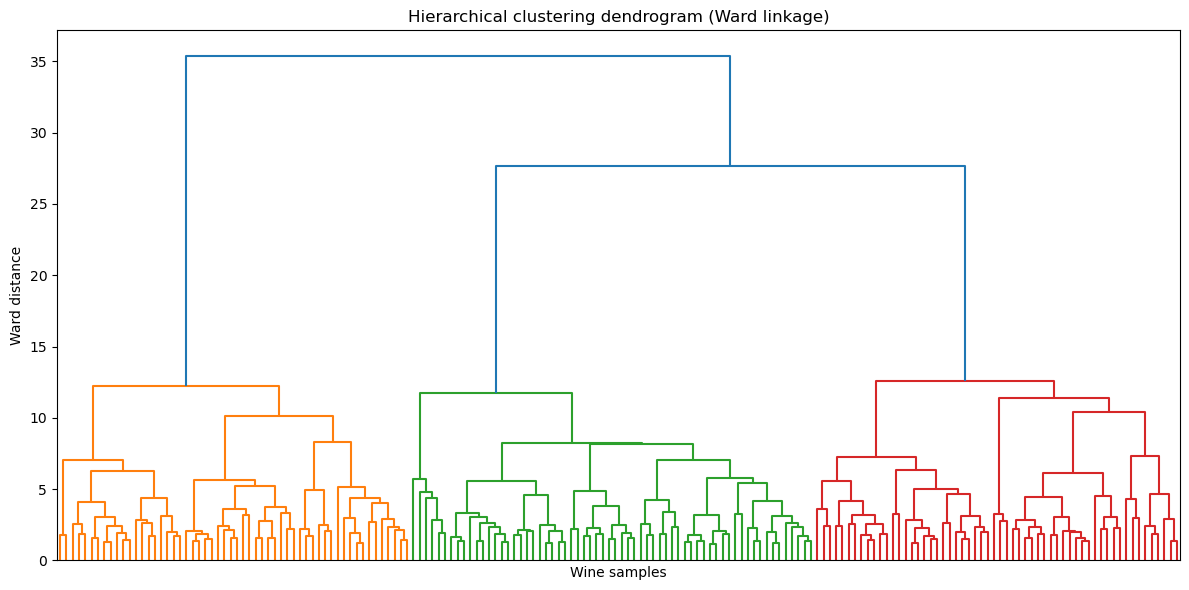

In [41]:
linkage_matrix = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, no_labels=True)
plt.title("Hierarchical clustering dendrogram (Ward linkage)")
plt.xlabel("Wine samples")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

In [42]:
hierarchical = AgglomerativeClustering(
    n_clusters=SELECTED_K,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

hierarchical_silhouette = silhouette_score(X_scaled, hierarchical_labels)
hierarchical_ari_vs_kmeans = adjusted_rand_score(
    kmeans_labels,
    hierarchical_labels
)

print("Hierarchical silhouette:", round(hierarchical_silhouette, 3))
print("Hierarchical vs. K-Means ARI:", round(hierarchical_ari_vs_kmeans, 3))

display(pd.DataFrame({
    "KMeans": pd.Series(kmeans_labels).value_counts().sort_index(),
    "Hierarchical": pd.Series(hierarchical_labels).value_counts().sort_index()
}))

Hierarchical silhouette: 0.277
Hierarchical vs. K-Means ARI: 0.853


,KMeans,Hierarchical
0,65,58
1,51,56
2,62,64


In [43]:
method_comparison = pd.DataFrame([
    {
        "method": "K-Means",
        "k": SELECTED_K,
        "silhouette": silhouette_score(X_scaled, kmeans_labels),
        "metadata_ARI": adjusted_rand_score(metadata, kmeans_labels)
    },
    {
        "method": "Hierarchical Ward",
        "k": SELECTED_K,
        "silhouette": hierarchical_silhouette,
        "metadata_ARI": adjusted_rand_score(metadata, hierarchical_labels)
    }
])

display(method_comparison)
print("Assignment agreement between methods:",
      round(hierarchical_ari_vs_kmeans, 3))

,method,k,silhouette,metadata_ARI
0,K-Means,3,0.285,0.897
1,Hierarchical Ward,3,0.277,0.790


Assignment agreement between methods: 0.853


### Comparison
K-Means and Ward hierarchical clustering employ different algorithms for the computations. Similar results, therefore, indicate that the general segregation is not exclusively reliant on one approach. The dissimilarities similarly provide useful information, as they highlight the areas where the outcome depends on the method used for the analysis.

## Production Readiness

### Guardrails
Confirm that the feature schema, numeric types, missingness, finite values, and expected measurement units have been validated before scoring. Fail fast when a required feature is missing or malformed.

### Reproducibility record
Keep a record of the dataset version/hash, the feature names and order, the scaler parameters, the random seed, the K-Means `n_init`, the selected `k`, algorithm, versions, the cluster counts, the silhouette score, the stability ARI, and model artifact.

### Monitoring
Monitor the feature missingness and non-finite values, distribution drift, cluster proportions, centroid distances, unexpected distance values, and cluster-quality proxies after ground truth has been established or audit data become available.

### Retraining triggers
Retrain the model when there are shifts in feature distributions, changes in cluster proportions beyond an approved range, increases in centroid distances, or degradations in cluster-quality/stability measures.

### Rollback
Keep a copy of the last validated clustering artifact. Rollback if the model fails schema checks, creates unacceptable cluster proportions, or has materially worse stability or quality metrics than the current version.

### Cost
This dataset is small, meaning that K-Means and hierarchical clustering are both inexpensive. For much larger datasets, more scalable approaches such as MiniBatchKMeans can reduce fitting cost while keeping the same validation and monitoring principles.

## Experiment Log

In [44]:
experiment_log = pd.DataFrame([{
    "timestamp": pd.Timestamp.now(),
    "dataset_rows": X_raw.shape[0],
    "features": X_raw.shape[1],
    "method": "KMeans",
    "k": SELECTED_K,
    "random_state": RANDOM_STATE,
    "n_init": KMEANS_N_INIT,
    "silhouette": silhouette_score(X_scaled, kmeans_labels),
    "stability_mean_ARI": selected_stability_row["mean_pairwise_ARI"],
    "metadata_ARI": metadata_ari,
    "hierarchical_ARI_vs_KMeans": hierarchical_ari_vs_kmeans
}])

display(experiment_log)

,timestamp,dataset_rows,features,method,k,random_state,n_init,silhouette,stability_mean_ARI,metadata_ARI,hierarchical_ARI_vs_KMeans
0,2026-09-16 18:33:01.301582,178,13,KMeans,3,42,20,0.285,1.000,0.897,0.853


## Final Summary

I performed validation of the dataset before cluster analysis, leaving cultivar labels as metadata only. The choice of the standardization method was justified by the fact that the chemical features in the dataframe have different scales. The evaluation of K-Means algorithm was conducted using elbow/inertia plots, silhouette scores, and stability checks across various seeds. The three-cluster solution was visualized using the first two principal components extracted during the PCA. The Ward linkage algorithm was applied as an alternative approach to hierarchical clustering. The description of each cluster was based on the actual measurements rather than the cultivar labels, which provide a more objective basis for analysis. For practical application, I would use schema guardrails, reproducibility checks, drift detection, cluster stability analysis, and explicit retraining triggers.